# 02 — Features y prevención de fuga

Las features se construyen exclusivamente con datos disponibles antes de la predicción: SMILES y condiciones de fase móvil/flujo. Los parámetros aprendidos (imputación y escalado) viven dentro del pipeline de scikit-learn y se ajustan solo en cada pliegue de entrenamiento.

In [1]:
from pathlib import Path
import os
import sys
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.datos import load_snapshot
from src.pipeline import FEATURE_COLUMNS, RAW_FEATURE_COLUMNS, MoleculeConditionFeatures, valid_smiles_mask
from src.splits import create_or_load_holdout, stratified_compound_sample

frame, metadata = load_snapshot()
valid = valid_smiles_mask(frame)
all_data = frame.loc[valid & frame["inchikey"].notna()].reset_index(drop=True)
train, holdout, split_metadata = create_or_load_holdout(all_data, source_sha256=metadata["sha256"])
data, sample_metadata = stratified_compound_sample(train, max_compounds=12_000, random_state=42)
X_raw = data.loc[:, RAW_FEATURE_COLUMNS]
feature_builder = MoleculeConditionFeatures()
X_features = feature_builder.fit_transform(X_raw)
y = data["tiempo_retencion"].astype(float)
print(f"Split completo: train={len(train):,}, holdout={len(holdout):,}; muestra estratificada de desarrollo={sample_metadata['compounds']:,} compuestos / {len(data):,} filas")
print(f"{X_raw.shape[1]} entradas disponibles -> {X_features.shape[1]} features derivadas; la evidencia con target usa solo train-sample")
display(X_features.head())

Split completo: train=122,370, holdout=30,216; muestra estratificada de desarrollo=12,000 compuestos / 19,406 filas
4 entradas disponibles -> 16 features derivadas; la evidencia con target usa solo train-sample


,mol_weight,mol_logp,mol_tpsa,mol_h_donors,mol_h_acceptors,mol_rotatable_bonds,mol_ring_count,mol_aromatic_rings,mol_fraction_csp3,elu_a_h2o,elu_a_meoh,elu_a_acn,elu_b_h2o,elu_b_meoh,elu_b_acn,flow_ml_min
0,326.849,3.44870,41.90,0.0,4.0,4.0,2.0,1.0,0.466667,100.0,0.0,0.0,0.0,0.0,100.0,0.1
1,384.501,2.31784,57.69,0.0,4.0,3.0,4.0,2.0,0.380952,100.0,0.0,0.0,0.0,0.0,100.0,0.1
2,468.941,3.70590,88.77,0.0,6.0,8.0,4.0,3.0,0.333333,100.0,0.0,0.0,0.0,0.0,100.0,0.1
3,474.587,1.61090,113.42,1.0,8.0,7.0,4.0,3.0,0.500000,100.0,0.0,0.0,0.0,0.0,100.0,0.6
4,372.490,4.27580,50.80,1.0,5.0,5.0,4.0,2.0,0.450000,100.0,0.0,0.0,0.0,0.0,100.0,0.1


,spearman,no_faltantes_%
elu_a_acn,-0.000,100.000
elu_a_h2o,0.059,100.000
elu_a_meoh,-0.058,100.000
elu_b_acn,0.154,100.000
elu_b_h2o,0.067,100.000
elu_b_meoh,-0.153,99.681
flow_ml_min,-0.705,96.042
mol_aromatic_rings,0.497,100.000
mol_fraction_csp3,-0.229,100.000
mol_h_acceptors,0.040,100.000


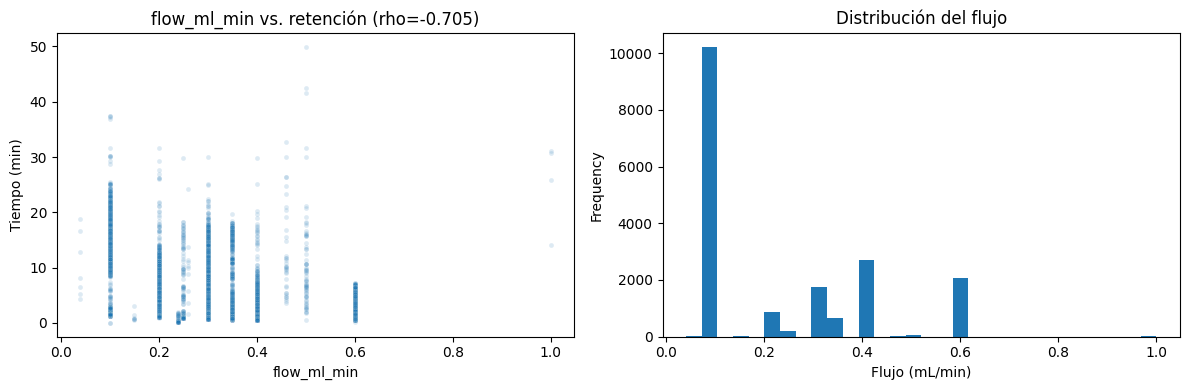

In [2]:
feature_evidence = X_features.assign(tiempo_retencion=y).corr(method="spearman")["tiempo_retencion"].drop("tiempo_retencion").dropna()
feature_evidence = feature_evidence.reindex(feature_evidence.abs().sort_values(ascending=False).index)
display(pd.DataFrame({"spearman": feature_evidence, "no_faltantes_%": 100 * X_features.notna().mean()} ).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = feature_evidence.index[0]
sns.scatterplot(x=X_features[top], y=y, alpha=0.15, s=12, ax=axes[0])
axes[0].set(title=f"{top} vs. retención (rho={feature_evidence[top]:.3f})", ylabel="Tiempo (min)")
X_features["flow_ml_min"].plot(kind="hist", bins=30, ax=axes[1], title="Distribución del flujo")
axes[1].set_xlabel("Flujo (mL/min)")
plt.tight_layout()
plt.show()

## Decisiones de diseño

| Feature derivada | Evidencia a reportar | Disponible al inferir | Tratamiento |
|---|---|---|---|
| Descriptores RDKit (peso molecular, LogP, TPSA, donadores/aceptores, anillos y fracción sp3) desde SMILES | La tabla de correlaciones y la cobertura del bloque anterior muestran variación molecular y asociación con la retención. | Sí: SMILES del compuesto nuevo. | Numérica; imputación por mediana y escalado dentro de `Pipeline`. |
| Fracciones H2O/MeOH/ACN de las fases A y B | Las fracciones observadas resumen la composición de la fase móvil y son reproducibles desde la descripción del método. | Sí: receta de elución. | Numérica; los valores no parseados se imputan solo dentro de cada fold. |
| Flujo (mL/min) | La distribución anterior cuantifica la variación del método. | Sí: parámetro operativo del método. | Numérica; imputación y escalado dentro de `Pipeline`. |

La transformación de SMILES/receta es determinista y no consulta el target. No se incluyen tiempo de retención, factor de retención ni etiquetas derivadas del resultado como predictores.